In [1]:
#first, we import our libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV

from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [89]:
fellows_data = pd.read_csv('data/fellowship_data.csv')
fellows_data.head()

,Name,Gender,Age,City,Graduate,Accepted
0,Kemi Bello,Female,25,Ilorin,Yes,Yes
1,Ngozi Afolabi,Female,31,Ilorin,Yes,Yes
2,Peace Afolabi,Female,30,Kano,Yes,No
3,Ngozi Afolabi,Female,35,Ilorin,Yes,Yes
4,Mariam Bello,Female,20,Ilorin,Yes,Yes


In [90]:
features = ['Age', 'City', 'Gender', 'Graduate']

target = ['Accepted']

In [104]:
x = fellows_data[features].copy()
y = fellows_data[target].copy()

In [105]:
x.head()

,Age,City,Gender,Graduate
0,25,Ilorin,Female,Yes
1,31,Ilorin,Female,Yes
2,30,Kano,Female,Yes
3,35,Ilorin,Female,Yes
4,20,Ilorin,Female,Yes


In [106]:
y.head()

,Accepted
0,Yes
1,Yes
2,No
3,Yes
4,Yes


In [107]:
x['Gender'] = x['Gender'].apply(lambda x: 1 if x == 'Female' else 0)

y['Accepted'] = y['Accepted']. apply(lambda y: 1 if y == 'Yes' else 0)

In [109]:
x['City'] = x['City'].apply(lambda x: 1 if x == 'Ilorin' else 0)

In [112]:
x['Graduate'] = x['Graduate'].apply(lambda x: 1 if x =='Yes' else 0)

In [113]:
x.head()

,Age,City,Gender,Graduate
0,25,1,1,1
1,31,1,1,1
2,30,0,1,1
3,35,1,1,1
4,20,1,1,1


In [114]:
y.head()

,Accepted
0,1
1,1
2,0
3,1
4,1


In [115]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

In [116]:
print("Training Data :", x_train.shape)
print("Testing Data :", x_test.shape)

print('____________')


print("Training Data :", y_train.shape)
print("Testing Data :", y_test.shape)

Training Data : (80, 4)
Testing Data : (20, 4)
____________
Training Data : (80, 1)
Testing Data : (20, 1)


In [117]:
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

**Train Logistic Regression Model**

In [118]:
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(x_train_scaled, y_train)

C:\Users\adeol\anaconda3\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [65]:
logistic_predictions = logistic_model.predict(x_test_scaled)
logistic_accuracy = accuracy_score(y_test, logistic_predictions)

print('Logistic Training Accuracy:', logistic_accuracy)

Logistic Training Accuracy: 1.0


In [67]:
print(classification_report(y_test, logistic_predictions))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         8
           1       1.00      1.00      1.00        12

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



**Train Decision Tree Model**

In [69]:
tree_model = DecisionTreeClassifier(max_depth=3, random_state=42)

tree_model.fit(x_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [70]:
tree_predictions = tree_model.predict(x_test)
tree_accuracy = accuracy_score(y_test, tree_predictions)

print('Desicion Tree Accuracy:', tree_accuracy)

Desicion Tree Accuracy: 1.0


In [72]:
print(classification_report(y_test, tree_predictions))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         8
           1       1.00      1.00      1.00        12

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



**Comparing The Two Models**

In [81]:
result = pd.DataFrame({
    'Model':['Logistic Regression', 'Decision Tree'],

    'Accuracy':[logistic_accuracy, tree_accuracy]       
    
})

result

,Model,Accuracy
0,Logistic Regression,1.0
1,Decision Tree,1.0


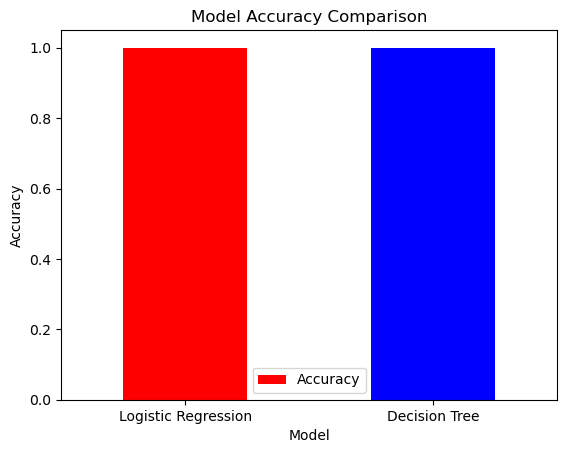

In [86]:
Colours = ['Red', 'Blue']
result.plot(
    x='Model',
    y='Accuracy',
kind='bar',
color=Colours
)
plt.title('Model Accuracy Comparison')
plt.xlabel('Model')
plt.ylabel('Accuracy')
plt.xticks(rotation=0)
plt.show()

In [119]:
fellows_data.groupby(['Graduate','City'])['Accepted'].value_counts()

Graduate  City           Accepted
No        Abuja          No           3
          Benin City     No           1
          Enugu          No           2
          Kano           No           1
          Lagos          No           3
          Port Harcourt  No           1
          Sokoto         No           1
Yes       Abuja          No           1
          Benin City     No           1
          Enugu          No           3
          Ibadan         No           6
          Ilorin         Yes         60
                         No           2
          Kaduna         No           4
          Kano           No           2
          Lagos          No           3
          Osogbo         No           2
          Port Harcourt  No           1
          Sokoto         No           3
Name: count, dtype: int64